# EDA: Rock / Paper / Scissors z HaGRID (`dataset/dataset_origin_new`)

Źródło: `cj-mills/hagrid-classification-512p-no-gesture-150k` (Hugging Face), gesty `fist → rock`,
`palm → paper`, `peace → scissors`. Zbiór zbudowany przez `load_dataset.py hagrid`.

Pytania:
1. Ile jest zdjęć w każdej klasie i w każdym splicie (train / val / test)?
2. Czy pliki są poprawne, jakie mają rozmiary, i czy sam rozmiar/proporcje nie zdradzają klasy?
3. Jak wyglądają obrazy?
4. Czy są duplikaty (dokładne i prawie identyczne) **między** train a val/test, czyli czy wynik
   ~98.5% na teście może być zawyżony przez wyciek?

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image


def find_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    raise FileNotFoundError("Nie znaleziono pyproject.toml")


ROOT = find_root(Path.cwd().resolve())
sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "dataset" / "dataset_origin_new"  # ten sam katalog co w train.py --data-dir
OUT_DIR = ROOT / "outputs" / "eda" / "hagrid"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "val", "test"]
CLASSES = sorted(p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir())  # kolejność jak w ImageFolder
SEED = 42

sns.set_theme(style="whitegrid")
PALETTE = dict(zip(CLASSES, sns.color_palette("tab10", len(CLASSES))))
pd.set_option("display.precision", 3)

info = json.loads((DATA_DIR / "dataset_info.json").read_text(encoding="utf-8"))
split_csv = pd.read_csv(DATA_DIR / "split.csv")
print(DATA_DIR, CLASSES)
print({k: info[k] for k in ("source", "label_map", "per_class", "val_ratio", "test_ratio", "seed")})

C:\Users\nicol\Desktop\studia\projekt_gielczyk\papier_kamien\dataset\dataset_origin_new ['paper', 'rock', 'scissors']
{'source': 'hf:cj-mills/hagrid-classification-512p-no-gesture-150k', 'label_map': {'rock': 'fist', 'paper': 'palm', 'scissors': 'peace'}, 'per_class': 6882, 'val_ratio': 0.15, 'test_ratio': 0.15, 'seed': 42}


## 0. Jedno przejście po danych

Każdy obraz czytamy raz z dysku (dokładnie te pliki, które widzi `ImageFolder` w `train.py`) i liczymy:
rozmiar, tryb, MD5, średnią jasność/kolor oraz miniaturę 48×32 (do wyszukiwania prawie-duplikatów).

In [2]:
records, thumbs = [], []
files = [(s, c, f) for s in SPLITS for c in CLASSES for f in sorted((DATA_DIR / s / c).iterdir())]
for split, label, f in files:
    raw = f.read_bytes()
    rec = {"split": split, "label": label, "file": f.name, "path": f"{split}/{label}/{f.name}",
           "bytes": len(raw), "md5": hashlib.md5(raw).hexdigest(), "error": None}
    try:
        img = Image.open(f)
        rec.update(width=img.width, height=img.height, mode=img.mode, format=img.format)
        rgb = np.asarray(img.convert("RGB"), dtype=np.float32)
        rec.update(mean_r=rgb[..., 0].mean(), mean_g=rgb[..., 1].mean(), mean_b=rgb[..., 2].mean(),
                   brightness=rgb.mean(), contrast=rgb.mean(2).std())
        thumbs.append(np.asarray(img.convert("L").resize((48, 32), Image.BILINEAR), dtype=np.float32).ravel())
    except Exception as e:  # noqa: BLE001
        rec["error"] = repr(e)
        thumbs.append(np.zeros(48 * 32, dtype=np.float32))
    records.append(rec)

df = pd.DataFrame(records)
df["aspect"] = df["width"] / df["height"]
thumbs = np.stack(thumbs)
print(len(df), "obrazów")

20646 obrazów


## 1. Liczba zdjęć na klasę i split

In [3]:
counts = pd.crosstab(df["split"], df["label"], margins=True, margins_name="razem").reindex([*SPLITS, "razem"])
counts["udział"] = (counts["razem"] / len(df)).round(3)
display(counts)

# zgodność z dataset_info.json i split.csv
expected = pd.DataFrame(info["counts"]).T.reindex(SPLITS)[CLASSES]
assert (counts.loc[SPLITS, CLASSES].values == expected.values).all(), "liczności różnią się od dataset_info.json"
assert set(df["path"]) == set(split_csv["path"]), "pliki na dysku różnią się od split.csv"
print("zgodne z dataset_info.json i split.csv")

label,paper,rock,scissors,razem,udział
split,,,,,
train,4915,4916,4915,14746,0.714
val,983,983,984,2950,0.143
test,984,983,983,2950,0.143
razem,6882,6882,6882,20646,1.000


zgodne z dataset_info.json i split.csv


,HF (fist/palm/peace),w datasecie,odrzucone (balansowanie)
paper,7050,6882,168
rock,6882,6882,0
scissors,6965,6882,83


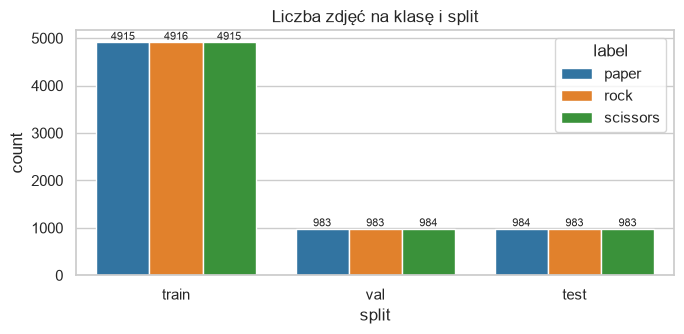

In [4]:
# Pełny zbiór HF (przed balansowaniem) vs to, co trafiło do datasetu
HF_COUNTS = {"rock": 6882, "paper": 7050, "scissors": 6965}  # statystyki datasets-server HF, split train, partial=False
summary = pd.DataFrame({"HF (fist/palm/peace)": HF_COUNTS, "w datasecie": df["label"].value_counts()}).loc[CLASSES]
summary["odrzucone (balansowanie)"] = summary.iloc[:, 0] - summary.iloc[:, 1]
display(summary)

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.countplot(data=df, x="split", hue="label", order=SPLITS, palette=PALETTE, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fontsize=8)
ax.set_title("Liczba zdjęć na klasę i split")
fig.tight_layout(); fig.savefig(OUT_DIR / "class_counts.png", dpi=150); plt.show()

## 2. Integralność plików i rozmiary

In [5]:
print("uszkodzone pliki:", df["error"].notna().sum())
display(df[["mode", "format"]].value_counts().to_frame("n"))
display(df.groupby("label")[["width", "height", "aspect", "bytes"]].describe().T.round(2))

uszkodzone pliki: 0


,,n
mode,format,
RGB,JPEG,20646


label            paper      rock  scissors
width  count   6882.00   6882.00   6882.00
       mean     507.16    504.43    503.42
       std       21.35     27.21     30.00
       min      294.00    176.00    155.00
       25%      512.00    512.00    512.00
       50%      512.00    512.00    512.00
       75%      512.00    512.00    512.00
       max      512.00    512.00    512.00
height count   6882.00   6882.00   6882.00
       mean     508.45    507.93    508.27
       std       20.14     21.69     21.75
       min      240.00    144.00    206.00
       25%      512.00    512.00    512.00
       50%      512.00    512.00    512.00
       75%      512.00    512.00    512.00
       max      512.00    512.00    512.00
aspect count   6882.00   6882.00   6882.00
       mean       1.00      0.99      0.99
       std        0.05      0.06      0.06
       min        0.58      0.53      0.48
       25%        1.00      1.00      1.00
       50%        1.00      1.00      1.00
       75%        1.00      1.00      1.00
       max        1.80      1.87      1.71
bytes  count   6882.00   6882.00   6882.00
       mean   24299.98  23543.15  24219.59
       std     7542.72   7922.20   7812.12
       min     8635.00   4479.00   5576.00
       25%    19175.25  18143.50  18875.75
       50%    23247.00  22452.50  23128.50
       75%    28046.75  27462.00  28251.75
       max    72571.00  77543.00  78778.00

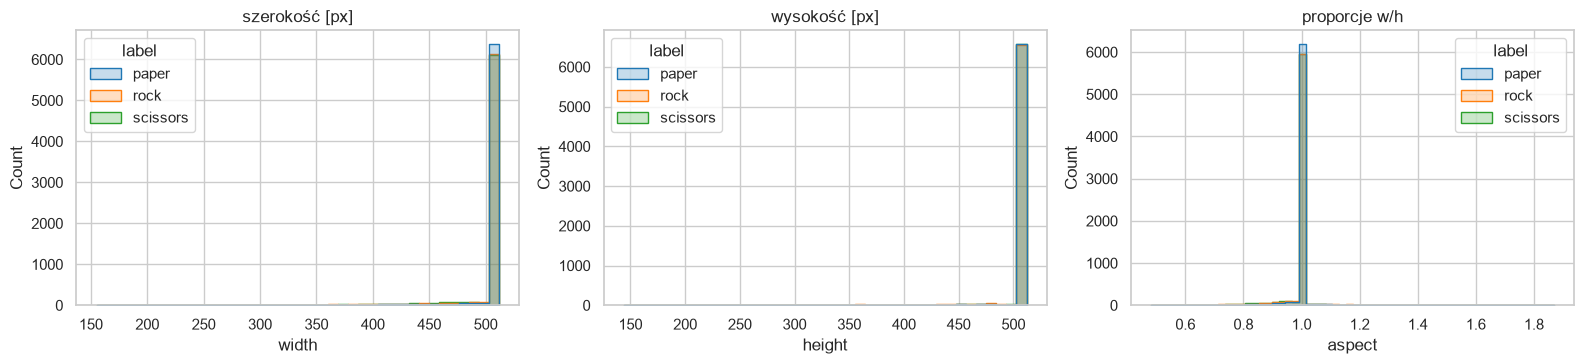

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(data=df, x="width", hue="label", palette=PALETTE, element="step", bins=40, ax=axes[0])
sns.histplot(data=df, x="height", hue="label", palette=PALETTE, element="step", bins=40, ax=axes[1])
sns.histplot(data=df, x="aspect", hue="label", palette=PALETTE, element="step", bins=60, ax=axes[2])
axes[0].set_title("szerokość [px]"); axes[1].set_title("wysokość [px]"); axes[2].set_title("proporcje w/h")
fig.tight_layout(); fig.savefig(OUT_DIR / "sizes.png", dpi=150); plt.show()

### 2a. Czy sam rozmiar zdradza klasę?

Obrazy to wycinki wokół dłoni, więc ich proporcje zależą od kształtu gestu (otwarta dłoń jest szersza,
„peace” wyższe). `Resize((224, 224))` w `src/transforms.py` rozciąga obraz do kwadratu, więc ta informacja
częściowo zostaje w obrazie. Sprawdzamy, jak daleko zajdzie klasyfikator **tylko** na (szerokość, wysokość,
rozmiar pliku, średni kolor), bez patrzenia na piksele. Trenowany na train, oceniany na test.

In [7]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score

def shortcut_acc(cols):
    tr, te = df[df["split"] == "train"], df[df["split"] == "test"]
    clf = HistGradientBoostingClassifier(random_state=SEED).fit(tr[cols], tr["label"])
    return accuracy_score(te["label"], clf.predict(te[cols]))

shortcuts = pd.Series({
    "losowo": 1 / len(CLASSES),
    "width, height, aspect": shortcut_acc(["width", "height", "aspect"]),
    "bytes": shortcut_acc(["bytes"]),
    "średni kolor + jasność + kontrast": shortcut_acc(["mean_r", "mean_g", "mean_b", "brightness", "contrast"]),
    "wszystko powyżej": shortcut_acc(["width", "height", "aspect", "bytes", "mean_r", "mean_g", "mean_b",
                                      "brightness", "contrast"]),
}, name="test accuracy")
display(shortcuts.to_frame())

,test accuracy
losowo,0.333
"width, height, aspect",0.349
bytes,0.341
średni kolor + jasność + kontrast,0.332
wszystko powyżej,0.361


## 3. Przykładowe obrazy

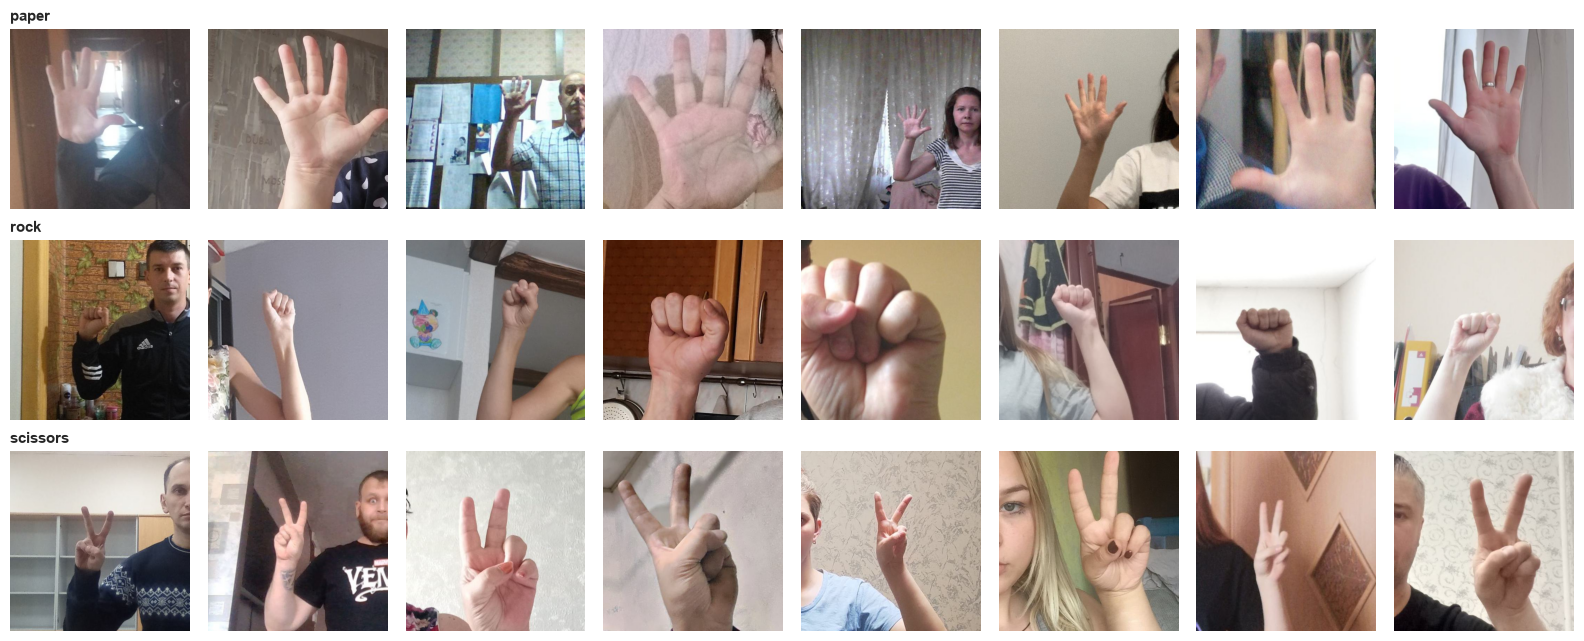

In [8]:
rng = np.random.default_rng(SEED)
n = 8
fig, axes = plt.subplots(len(CLASSES), n, figsize=(2 * n, 2.2 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    sample = df[(df["label"] == c) & (df["split"] == "train")].sample(n, random_state=SEED)
    for j, (ax, p) in enumerate(zip(axes[i], sample["path"])):
        ax.imshow(Image.open(DATA_DIR / p)); ax.axis("off")
        if j == 0:
            ax.set_title(c, loc="left", fontsize=11, fontweight="bold")
fig.tight_layout(); fig.savefig(OUT_DIR / "samples.png", dpi=120); plt.show()

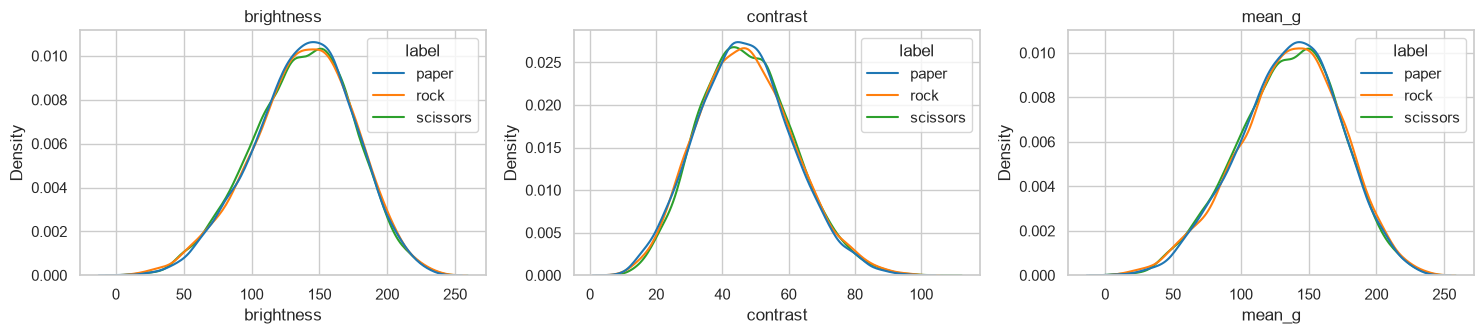

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["brightness", "contrast", "mean_g"]):
    sns.kdeplot(data=df, x=col, hue="label", palette=PALETTE, common_norm=False, ax=ax)
    ax.set_title(col)
fig.tight_layout(); fig.savefig(OUT_DIR / "color_stats.png", dpi=150); plt.show()

## 4. Wyciek między splitami

### 4a. Dokładne duplikaty (MD5)

In [10]:
dup = df[df.duplicated("md5", keep=False)].sort_values("md5")
print("obrazów z duplikatem MD5:", len(dup), "| grup:", dup["md5"].nunique())
cross = dup.groupby("md5").agg(splits=("split", lambda s: tuple(sorted(set(map(str, s))))),
                               labels=("label", lambda s: tuple(sorted(set(s)))))
print("grupy MD5 rozdzielone między splity:", (cross["splits"].map(len) > 1).sum())
print("grupy MD5 z różnymi etykietami:", (cross["labels"].map(len) > 1).sum())
display(dup.head(10)[["path", "md5", "bytes"]])

obrazów z duplikatem MD5: 0 | grup: 0
grupy MD5 rozdzielone między splity: 0
grupy MD5 z różnymi etykietami: 0


,path,md5,bytes


### 4b. Prawie-duplikaty: najbliższy sąsiad z train dla każdego obrazu z testu

Dwie miary podobieństwa:
- **piksele**: korelacja miniatur 48×32 w skali szarości (to samo kryterium co grupowanie w `load_dataset.py hagrid`),
- **cechy CNN**: cosinus między embeddingami MobileNetV3 (ImageNet). Łapie też to samo ujęcie
  po przeskalowaniu/przesunięciu i podobne tło/osobę.

Dla porównania: rozkład podobieństwa test→train zestawiamy z test→test (inne obrazy z testu). Jeśli test jest
dużo bliżej train niż sam siebie, to znak wycieku.

In [11]:
def normalize(x, center=False):
    if center:  # korelacja Pearsona = cosinus po odjęciu średniej
        x = x - x.mean(1, keepdims=True)
    return x / np.linalg.norm(x, axis=1, keepdims=True).clip(1e-8)

def nearest(query, base, exclude_self=False, chunk=2048):
    best_sim, best_idx = np.empty(len(query)), np.empty(len(query), dtype=int)
    for s in range(0, len(query), chunk):
        sim = query[s:s + chunk] @ base.T
        if exclude_self:
            sim[np.arange(sim.shape[0]), np.arange(s, s + sim.shape[0])] = -np.inf
        best_idx[s:s + chunk] = sim.argmax(1)
        best_sim[s:s + chunk] = sim.max(1)
    return best_sim, best_idx

idx = {s: np.flatnonzero(df["split"] == s) for s in SPLITS}
T = normalize(thumbs, center=True)
px_tt_sim, px_tt_idx = nearest(T[idx["test"]], T[idx["train"]])
px_te_sim, _ = nearest(T[idx["test"]], T[idx["test"]], exclude_self=True)

In [12]:
import torch
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small

from src.transforms import build_transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
backbone = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1)
backbone.classifier = torch.nn.Identity()
backbone.eval().to(device)
tf = build_transforms(224, train=False)

embs = []
with torch.no_grad():
    for s in range(0, len(df), 256):
        batch = torch.stack([tf(Image.open(DATA_DIR / p).convert("RGB")) for p in df["path"].iloc[s:s + 256]])
        embs.append(backbone(batch.to(device)).cpu().numpy())
E = normalize(np.concatenate(embs))
cnn_tt_sim, cnn_tt_idx = nearest(E[idx["test"]], E[idx["train"]])
cnn_te_sim, _ = nearest(E[idx["test"]], E[idx["test"]], exclude_self=True)

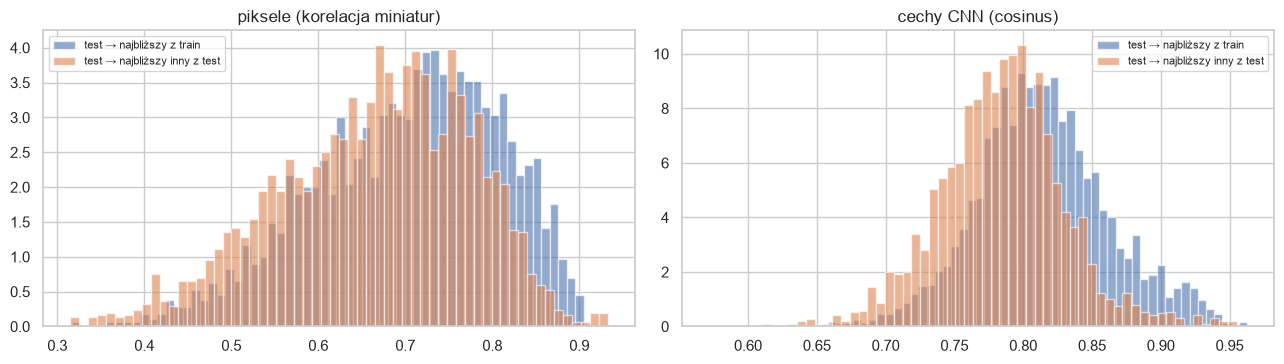

,piksele test→train,piksele test→test,CNN test→train,CNN test→test
>= 0.9,0.27,0.47,5.56,1.53
>= 0.95,0.00,0.00,0.14,0.14
>= 0.98,0.00,0.00,0.00,0.00
>= 0.99,0.00,0.00,0.00,0.00


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (name, tt, te) in zip(axes, [("piksele (korelacja miniatur)", px_tt_sim, px_te_sim),
                                     ("cechy CNN (cosinus)", cnn_tt_sim, cnn_te_sim)]):
    ax.hist(tt, bins=60, alpha=0.6, label="test → najbliższy z train", density=True)
    ax.hist(te, bins=60, alpha=0.6, label="test → najbliższy inny z test", density=True)
    ax.set_title(name); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "nearest_neighbor_similarity.png", dpi=150); plt.show()

thresholds = [0.90, 0.95, 0.98, 0.99]
display(pd.DataFrame({
    "piksele test→train": [(px_tt_sim >= t).mean() for t in thresholds],
    "piksele test→test": [(px_te_sim >= t).mean() for t in thresholds],
    "CNN test→train": [(cnn_tt_sim >= t).mean() for t in thresholds],
    "CNN test→test": [(cnn_te_sim >= t).mean() for t in thresholds],
}, index=[f">= {t}" for t in thresholds]).mul(100).round(2))  # % obrazów z testu z sąsiadem powyżej progu

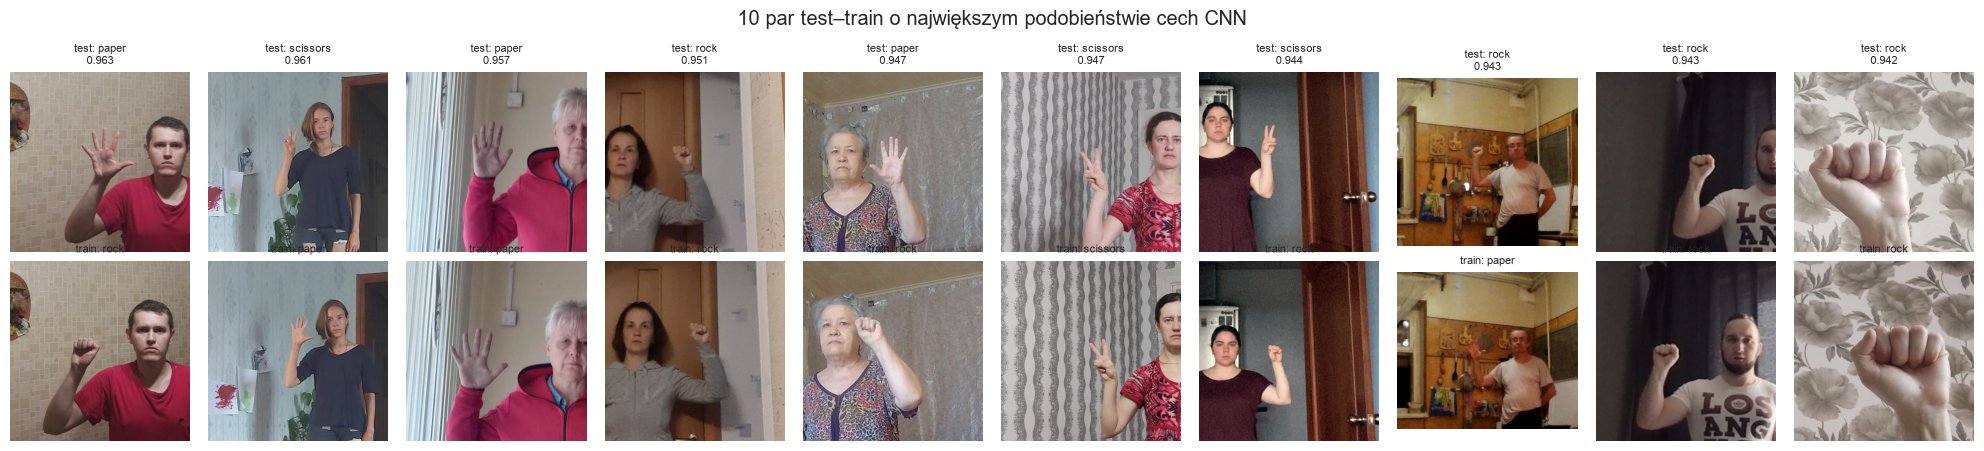

In [14]:
# Najbardziej podobne pary test-train wg cech CNN: czy to ta sama klatka / ta sama osoba?
order = np.argsort(-cnn_tt_sim)[:10]
fig, axes = plt.subplots(2, 10, figsize=(20, 4.6))
for j, k in enumerate(order):
    a, b = df.iloc[idx["test"][k]], df.iloc[idx["train"][cnn_tt_idx[k]]]
    axes[0, j].imshow(Image.open(DATA_DIR / a["path"])); axes[0, j].set_title(f"test: {a['label']}\n{cnn_tt_sim[k]:.3f}", fontsize=8)
    axes[1, j].imshow(Image.open(DATA_DIR / b["path"])); axes[1, j].set_title(f"train: {b['label']}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("10 par test-train o największym podobieństwie cech CNN")
fig.tight_layout(); fig.savefig(OUT_DIR / "top_test_train_pairs.png", dpi=120); plt.show()

In [15]:
# Czy k-NN na cechach ImageNet (bez trenowania!) już rozwiązuje zadanie? Wysoki wynik = zadanie jest łatwe,
# niekoniecznie wyciek. Porównanie 1-NN do train vs. etykieta.
y = df["label"].to_numpy()
knn_acc = (y[idx["train"]][cnn_tt_idx] == y[idx["test"]]).mean()
px_knn_acc = (y[idx["train"]][px_tt_idx] == y[idx["test"]]).mean()
print(f"1-NN na cechach MobileNetV3 (ImageNet, bez fine-tuningu): test accuracy = {knn_acc:.4f}")
print(f"1-NN na miniaturach pikseli:                              test accuracy = {px_knn_acc:.4f}")

1-NN na cechach MobileNetV3 (ImageNet, bez fine-tuningu): test accuracy = 0.6227
1-NN na miniaturach pikseli:                              test accuracy = 0.4468


In [16]:
# Pary test-train z tej samej sesji (ta sama osoba/tło): czy zwykle mają tę samą etykietę?
# Jeśli tak, model może „ściągać” z tła/osoby; jeśli nie, tło nic nie mówi o klasie.
same = y[idx["train"]][cnn_tt_idx] == y[idx["test"]]
bins = pd.cut(cnn_tt_sim, [0, 0.8, 0.85, 0.9, 1.0])
display(pd.DataFrame({"obrazów z testu": pd.Series(bins).value_counts().sort_index(),
                      "ta sama etykieta co sąsiad z train [%]": pd.Series(same).groupby(bins, observed=False).mean().mul(100).round(1)}))

,obrazów z testu,ta sama etykieta co sąsiad z train [%]
"(0.0, 0.8]",1158,63.2
"(0.8, 0.85]",1164,66.6
"(0.85, 0.9]",464,54.5
"(0.9, 1.0]",164,47.0


## 5. Wnioski

**Liczności.** 20 646 zdjęć, po 6882 na klasę (rock/paper/scissors). Pełny HF ma fist 6882 / palm 7050 / peace 6965,
nadmiar paper (168) i scissors (83) odrzucony losowo przy balansowaniu. Split 70/15/15:
train 14 746 (4915/4916/4915), val 2950, test 2950, w każdym splicie klasy po równo. Zgodne z `dataset_info.json` i `split.csv`.

**Pliki.** 0 uszkodzonych, wszystkie RGB JPEG, prawie wszystkie 512×512 (wycinki wokół dłoni, część mniejsza przy krawędzi kadru).

**Brak skrótów w metadanych.** Klasyfikator na samym rozmiarze / proporcjach / rozmiarze pliku / średnim kolorze daje 33-36% na teście
(losowo 33%), tych cech model nie może wykorzystać.

**Duplikaty.** 0 dokładnych duplikatów (MD5). Brak prawie identycznych klatek między splitami (korelacja pikseli ≥ 0.95: 0%).

**Te same osoby w train i test, TAK.** Najbardziej podobne pary test-train (sekcja 4b) to ta sama osoba w tym samym pokoju
z tej samej sesji nagraniowej. Split grupuje tylko prawie identyczne klatki, nie osoby, w danych z HF nie ma `user_id`.
Ale: dla par z tej samej sesji (cosinus CNN > 0.9) etykieta sąsiada z train zgadza się tylko w **47%** przypadków,
ta sama osoba pokazuje różne gesty, więc tło/osoba **nie zdradza klasy**. Wpływ na wynik testu jest więc najwyżej niewielki.

**Czy ~98.5% na teście jest wiarygodne?** Raczej tak: 3 bardzo różne gesty, kadr wycentrowany na dłoni, 15k obrazów treningowych.
Zadanie nie jest trywialne „za darmo” (1-NN na cechach ImageNet bez treningu: 62%, na pikselach: 45%), więc wynik to efekt uczenia,
nie wycieku. Uwaga: to wynik **in-domain** (te same osoby/sesje HaGRID), na zdjęciach z innej kamery/osób (np. telefon, `dataset_origin`)
może być wyraźnie gorzej; to warto sprawdzić osobno.

**Jeśli potrzebny ścisły podział po osobach:** pobrać adnotacje HaGRID (`user_id` per UUID obrazu, UUID jest w kolumnie `image.path`
w parquet) i dzielić `StratifiedGroupKFold` po `user_id` zamiast po grupach miniatur.
